<a href="https://colab.research.google.com/github/Atmajajnk/EDA-SENTIMENT-PENCOPOTAN-MENKEU-PURBAYA-ATMAJAJALUNARENDRAKISMA-26MA41D005-AMIKOMPURWOKERTO/blob/main/EDA_PENCOPOTAN_MENKEU_PURBAYA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA) Data Twitter Purbaya Yudhi Sadewa

Notebook ini dibuat berdasarkan file dataTwitter.xlsx yang diunggah. Jalankan seluruh sel secara berurutan di Google Colab.

### Tujuan EDA



1.   Memahami struktur dan kualitas data hasil crawling.
2.   Memeriksa data kosong, duplikasi, tipe data, bahasa, dan rentang waktu.
3. Menganalisis distribusi aktivitas tweet dan interaksi (like, retweet, reply, quote, view).
4. Melihat tren jumlah tweet dari waktu ke waktu.
5. Mengidentifikasi kata yang sering muncul sebagai gambaran awal isi percakapan.


## 1. Instalasi dan import library


In [ ]:
!pip -q install openpyxl wordcloud

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from wordcloud import WordCloud
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)

## 2. Memasukan dataset ke google collab

In [ ]:
import pandas as pd

# Lokasi file CSV di Google Drive
file_path = '/content/drive/MyDrive/Proyek/S2/Purbaya Yudhi Sadewa/dataTwitter.csv'

# Membaca CSV dengan encoding alternatif
data = pd.read_csv(file_path, encoding='latin1')

# Menampilkan ukuran dataset
print("Jumlah baris dan kolom:", data.shape)

# Menampilkan 5 data pertama
display(data.head())

Jumlah baris dan kolom: (3613, 33)


,type,id,url,twitterUrl,text,source,retweetCount,replyCount,likeCount,quoteCount,viewCount,createdAt,lang,bookmarkCount,isReply,inReplyToId,conversationId,inReplyToUserId,inReplyToUsername,isPinned,author,extendedEntities,card,place,entities,reply_to_user_results,quoted_tweet_results,quoted_tweet,retweeted_tweet,isConversationControlled,searchTermIndex,isQuote,isRetweet
0,tweet,2106613680893054987,https://x.com/suaradotcom/status/2106613680893054987,https://twitter.com/suaradotcom/status/2106613680893054987,Kembalinya Luky Alfirman ke lingkar pimpinan Kementerian Keuangan (Kemenkeu) memicu sorotan publik. \n\nSetelah semp...,NaN,3,0,4,1,814,Sun Oct 04 05:13:35 +0000 2026,in,0,False,NaN,2106613680893054987,NaN,NaN,False,"{'type': 'user', 'userName': 'suaradotcom', 'url': 'https://x.com/suaradotcom', 'twitterUrl': 'https://twitter.com/s...","{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/UiQEPcAuVZ', 'expanded_url'...",NaN,{},"{'hashtags': [{'indices': [2333, 2346], 'text': 'lukyalfirman'}, {'indices': [2347, 2356], 'text': 'pengamat'}, {'in...",NaN,NaN,NaN,NaN,False,0,NaN,NaN
1,tweet,2106378191623586058,https://x.com/VeritasArdentur/status/2106378191623586058,https://twitter.com/VeritasArdentur/status/2106378191623586058,Kebijakan tanda bintang itu dihapuskan ketika purbaya menjabat.\n\nhttps://t.co/0GbtCZLMQN.,NaN,1,3,10,0,2967,Sat Oct 03 13:37:50 +0000 2026,in,0,False,NaN,2106378191623586058,NaN,NaN,False,"{'type': 'user', 'userName': 'VeritasArdentur', 'url': 'https://x.com/VeritasArdentur', 'twitterUrl': 'https://twitt...",{},NaN,{},"{'urls': [{'display_url': 'money.kompas.com/read/2026/09/1 ', 'expanded_url': 'https://money.kompas.com/read/2026/09...",NaN,"{'rest_id': '2106376136989229209', 'result': {'__typename': 'Tweet', 'core': {'user_results': {'rest_id': '246882820...","{'type': 'tweet', 'id': '2106376136989229209', 'url': 'https://x.com/muttle9/status/2106376136989229209', 'twitterUr...",NaN,False,0,True,NaN
2,tweet,2106355674405912867,https://x.com/VeritasArdentur/status/2106355674405912867,https://twitter.com/VeritasArdentur/status/2106355674405912867,Itu paragraf pertama ngomongin sistem bintang di DJA. Bukan penandatanganan DIPA.\n\nSudah basi dan tidak berlaku di...,NaN,1,1,7,0,2256,Sat Oct 03 12:08:21 +0000 2026,in,3,False,NaN,2106355674405912867,NaN,NaN,False,"{'type': 'user', 'userName': 'VeritasArdentur', 'url': 'https://x.com/VeritasArdentur', 'twitterUrl': 'https://twitt...","{'media': [{'display_url': 'pic.x.com/LT6SX6qDou', 'expanded_url': 'https://x.com/VeritasArdentur/status/21063556744...",NaN,{},"{'urls': [{'display_url': 'money.kompas.com/read/2026/09/1 ', 'expanded_url': 'https://money.kompas.com/read/2026/09...",NaN,"{'rest_id': '2106348056438509654', 'result': {'__typename': 'Tweet', 'core': {'user_results': {'rest_id': '246882820...","{'type': 'tweet', 'id': '2106348056438509654', 'url': 'https://x.com/muttle9/status/2106348056438509654', 'twitterUr...",NaN,False,0,True,NaN
3,tweet,2106336567631679547,https://x.com/VeritasArdentur/status/2106336567631679547,https://twitter.com/VeritasArdentur/status/2106336567631679547,"Itu ketika tanda bintang masih berlaku.\n\nPurbaya sudah jelas2 menghapus sistem tersebut, dan sudah dikomunikasikan...",NaN,3,1,16,0,2888,Sat Oct 03 10:52:26 +0000 2026,in,0,False,NaN,2106336567631679547,NaN,NaN,False,"{'type': 'user', 'userName': 'VeritasArdentur', 'url': 'https://x.com/VeritasArdentur', 'twitterUrl': 'https://twitt...",{},NaN,{},"{'urls': [{'display_url': 'money.kompas.com/read/2026/09/1 ', 'expanded_url': 'https://money.kompas.com/read/2026/09...",NaN,"{'rest_id': '2106334098646290767', 'result': {'__typename': 'Tweet', 'core': {'user_results': {'rest_id': '246882820...","{'type': 'tweet', 'id': '2106334098646290767', 'url': 'https://x.com/muttle9/status/2106334098646290767', 'twitterUr...",NaN,False,0,True,NaN
4,tweet,2106331994527559750,https://x.com/VeritasArdentur/status/2106331994527559750,https://twitter.com/Ve

## 3. Memahami struktur dataset

In [ ]:
print("Jumlah baris:", data.shape[0])
print("Jumlah kolom:", data.shape[1])

print("\nNama kolom:")
print(data.columns.tolist())

print("\nTipe data setiap kolom:")
display(data.dtypes.astype(str).rename("tipe_data").to_frame())

print("\nInformasi dataset:")
data.info()

Jumlah baris: 3613
Jumlah kolom: 33

Nama kolom:
['type', 'id', 'url', 'twitterUrl', 'text', 'source', 'retweetCount', 'replyCount', 'likeCount', 'quoteCount', 'viewCount', 'createdAt', 'lang', 'bookmarkCount', 'isReply', 'inReplyToId', 'conversationId', 'inReplyToUserId', 'inReplyToUsername', 'isPinned', 'author', 'extendedEntities', 'card', 'place', 'entities', 'reply_to_user_results', 'quoted_tweet_results', 'quoted_tweet', 'retweeted_tweet', 'isConversationControlled', 'searchTermIndex', 'isQuote', 'isRetweet']

Tipe data setiap kolom:


,tipe_data
type,object
id,int64
url,object
twitterUrl,object
text,object
source,float64
retweetCount,int64
replyCount,int64
likeCount,int64
quoteCount,int64



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3613 entries, 0 to 3612
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   type                      3613 non-null   object 
 1   id                        3613 non-null   int64  
 2   url                       3613 non-null   object 
 3   twitterUrl                3613 non-null   object 
 4   text                      3612 non-null   object 
 5   source                    0 non-null      float64
 6   retweetCount              3613 non-null   int64  
 7   replyCount                3613 non-null   int64  
 8   likeCount                 3613 non-null   int64  
 9   quoteCount                3613 non-null   int64  
 10  viewCount                 3613 non-null   int64  
 11  createdAt                 3613 non-null   object 
 12  lang                      3613 non-null   object 
 13  bookmarkCount             3613 non-null   i

## 4. Membaca dataset CSV dengan penanganan Encoding


In [ ]:
file_path = '/content/drive/MyDrive/Proyek/S2/Purbaya Yudhi Sadewa/dataTwitter.csv'

# Coba beberapa encoding untuk mengatasi UnicodeDecodeError.
encodings = ['utf-8', 'utf-8-sig', 'cp1252', 'latin1']
data = None
for enc in encodings:
    try:
        data = pd.read_csv(file_path, encoding=enc, low_memory=False)
        print(f"Berhasil membaca file menggunakan encoding: {enc}")
        break
    except UnicodeDecodeError:
        print(f"Gagal dengan encoding {enc}, mencoba encoding berikutnya...")

if data is None:
    raise ValueError("File belum berhasil dibaca. Periksa format dan lokasi file.")

print("Ukuran dataset:", data.shape)
display(data.head())

Gagal dengan encoding utf-8, mencoba encoding berikutnya...
Gagal dengan encoding utf-8-sig, mencoba encoding berikutnya...
Berhasil membaca file menggunakan encoding: cp1252
Ukuran dataset: (3613, 33)


,type,id,url,twitterUrl,text,source,retweetCount,replyCount,likeCount,quoteCount,viewCount,createdAt,lang,bookmarkCount,isReply,inReplyToId,conversationId,inReplyToUserId,inReplyToUsername,isPinned,author,extendedEntities,card,place,entities,reply_to_user_results,quoted_tweet_results,quoted_tweet,retweeted_tweet,isConversationControlled,searchTermIndex,isQuote,isRetweet
0,tweet,2106613680893054987,https://x.com/suaradotcom/status/2106613680893054987,https://twitter.com/suaradotcom/status/2106613680893054987,Kembalinya Luky Alfirman ke lingkar pimpinan Kementerian Keuangan (Kemenkeu) memicu sorotan publik. \n\nSetelah semp...,NaN,3,0,4,1,814,Sun Oct 04 05:13:35 +0000 2026,in,0,False,NaN,2106613680893054987,NaN,NaN,False,"{'type': 'user', 'userName': 'suaradotcom', 'url': 'https://x.com/suaradotcom', 'twitterUrl': 'https://twitter.com/s...","{'media': [{'allow_download_status': {'allow_download': True}, 'display_url': 'pic.x.com/UiQEPcAuVZ', 'expanded_url'...",NaN,{},"{'hashtags': [{'indices': [2333, 2346], 'text': 'lukyalfirman'}, {'indices': [2347, 2356], 'text': 'pengamat'}, {'in...",NaN,NaN,NaN,NaN,False,0,NaN,NaN
1,tweet,2106378191623586058,https://x.com/VeritasArdentur/status/2106378191623586058,https://twitter.com/VeritasArdentur/status/2106378191623586058,Kebijakan tanda bintang itu dihapuskan ketika purbaya menjabat.\n\nhttps://t.co/0GbtCZLMQN.,NaN,1,3,10,0,2967,Sat Oct 03 13:37:50 +0000 2026,in,0,False,NaN,2106378191623586058,NaN,NaN,False,"{'type': 'user', 'userName': 'VeritasArdentur', 'url': 'https://x.com/VeritasArdentur', 'twitterUrl': 'https://twitt...",{},NaN,{},"{'urls': [{'display_url': 'money.kompas.com/read/2026/09/1…', 'expanded_url': 'https://money.kompas.com/read/2026/09...",NaN,"{'rest_id': '2106376136989229209', 'result': {'__typename': 'Tweet', 'core': {'user_results': {'rest_id': '246882820...","{'type': 'tweet', 'id': '2106376136989229209', 'url': 'https://x.com/muttle9/status/2106376136989229209', 'twitterUr...",NaN,False,0,True,NaN
2,tweet,2106355674405912867,https://x.com/VeritasArdentur/status/2106355674405912867,https://twitter.com/VeritasArdentur/status/2106355674405912867,Itu paragraf pertama ngomongin sistem bintang di DJA. Bukan penandatanganan DIPA.\n\nSudah basi dan tidak berlaku di...,NaN,1,1,7,0,2256,Sat Oct 03 12:08:21 +0000 2026,in,3,False,NaN,2106355674405912867,NaN,NaN,False,"{'type': 'user', 'userName': 'VeritasArdentur', 'url': 'https://x.com/VeritasArdentur', 'twitterUrl': 'https://twitt...","{'media': [{'display_url': 'pic.x.com/LT6SX6qDou', 'expanded_url': 'https://x.com/VeritasArdentur/status/21063556744...",NaN,{},"{'urls': [{'display_url': 'money.kompas.com/read/2026/09/1…', 'expanded_url': 'https://money.kompas.com/read/2026/09...",NaN,"{'rest_id': '2106348056438509654', 'result': {'__typename': 'Tweet', 'core': {'user_results': {'rest_id': '246882820...","{'type': 'tweet', 'id': '2106348056438509654', 'url': 'https://x.com/muttle9/status/2106348056438509654', 'twitterUr...",NaN,False,0,True,NaN
3,tweet,2106336567631679547,https://x.com/VeritasArdentur/status/2106336567631679547,https://twitter.com/VeritasArdentur/status/2106336567631679547,"Itu ketika tanda bintang masih berlaku.\n\nPurbaya sudah jelas2 menghapus sistem tersebut, dan sudah dikomunikasikan...",NaN,3,1,16,0,2888,Sat Oct 03 10:52:26 +0000 2026,in,0,False,NaN,2106336567631679547,NaN,NaN,False,"{'type': 'user', 'userName': 'VeritasArdentur', 'url': 'https://x.com/VeritasArdentur', 'twitterUrl': 'https://twitt...",{},NaN,{},"{'urls': [{'display_url': 'money.kompas.com/read/2026/09/1…', 'expanded_url': 'https://money.kompas.com/read/2026/09...",NaN,"{'rest_id': '2106334098646290767', 'result': {'__typename': 'Tweet', 'core': {'user_results': {'rest_id': '246882820...","{'type': 'tweet', 'id': '2106334098646290767', 'url': 'https://x.com/muttle9/status/2106334098646290767', 'twitterUr...",NaN,False,0,True,NaN
4,tweet,2106331994527559750,https://x.com/VeritasArdentur/status/2106331994527559750,https://twitter.com/Ve

## 5. Statistik Deskriptif dan pemeriksaan nilai kosong

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
type,3613,1,tweet,3613,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,3613.0,NaN,NaN,NaN,2063234058101911296.0,53122290887711992.0,1964969484030271744.0,2048681319257846016.0,2096887217750966784.0,2099792846005915648.0,2120893192224801024.0
url,3613,1862,https://x.com/PutriKariimah/status/2102202833798156590,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
twitterUrl,3613,1862,https://twitter.com/PutriKariimah/status/2102202833798156590,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,3612,1911,Jajaran menteri Kabinet Merah Putih didominasi lulusan universitas bergengsi di Indonesia.\n\nSejak reshuffle jilid...,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
retweetCount,3613.0,NaN,NaN,NaN,88.740105,641.940342,0.0,0.0,2.0,12.0,19475.0
replyCount,3613.0,NaN,NaN,NaN,17.338223,85.703813,0.0,0.0,1.0,7.0,3104.0
likeCount,3613.0,NaN,NaN,NaN,357.388874,2229.873382,0.0,2.0,9.0,36.0,46883.0
quoteCount,3613.0,NaN,NaN,NaN,16.020205,161.541438,0.0,0.0,0.0,2.0,5911.0


,jumlah_kosong,persentase_kosong
source,3613,100.00
retweeted_tweet,3613,100.00
quoted_tweet_results,3484,96.43
quoted_tweet,3363,93.08
reply_to_user_results,3281,90.81
inReplyToUsername,3242,89.73
inReplyToUserId,3242,89.73
inReplyToId,3103,85.88
isRetweet,2956,81.82
isQuote,2952,81.70


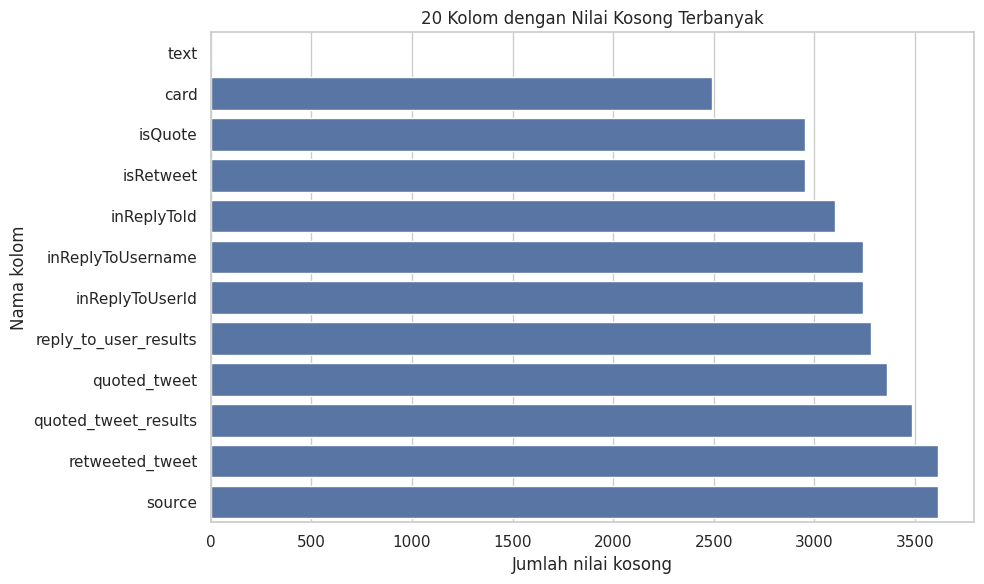

In [ ]:
display(data.describe(include='all').T)

missing = pd.DataFrame({
    'jumlah_kosong': data.isna().sum(),
    'persentase_kosong': (data.isna().mean() * 100).round(2)
}).sort_values('jumlah_kosong', ascending=False)

display(missing[missing['jumlah_kosong'] > 0])

missing_plot = missing[missing['jumlah_kosong'] > 0].head(20).sort_values('jumlah_kosong')
if len(missing_plot):
    plt.figure(figsize=(10, 6))
    sns.barplot(data=missing_plot.reset_index(), x='jumlah_kosong', y='index')
    plt.title('20 Kolom dengan Nilai Kosong Terbanyak')
    plt.xlabel('Jumlah nilai kosong')
    plt.ylabel('Nama kolom')
    plt.tight_layout()
    plt.show()

## 6. Pemeriksaan Duplikasi

In [ ]:
print("Duplikasi seluruh baris:", data.duplicated().sum())

if 'id' in data.columns:
    print("Jumlah ID unik:", data['id'].nunique(dropna=True))
    print("Duplikasi berdasarkan ID:", data['id'].duplicated().sum())

if 'text' in data.columns:
    print("Jumlah teks unik:", data['text'].nunique(dropna=True))
    print("Duplikasi berdasarkan teks:", data['text'].duplicated().sum())

# Buat salinan analisis dengan satu baris per ID.
# Data mentah (data) tetap dipertahankan agar tidak berubah.
if 'id' in data.columns:
    eda = data.drop_duplicates(subset=['id'], keep='first').copy()
elif 'text' in data.columns:
    eda = data.drop_duplicates(subset=['text'], keep='first').copy()
else:
    eda = data.drop_duplicates().copy()

print("Ukuran setelah deduplikasi:", eda.shape)

Duplikasi seluruh baris: 370
Jumlah ID unik: 1862
Duplikasi berdasarkan ID: 1751
Jumlah teks unik: 1911
Duplikasi berdasarkan teks: 1701
Ukuran setelah deduplikasi: (1862, 33)


## 7. Mengolah tanggal dan menentukan periode penelitian

In [ ]:
if 'createdAt' not in eda.columns:
    raise KeyError("Kolom 'createdAt' tidak ditemukan. Periksa nama kolom tanggal.")

# Format timestamp Twitter/X seperti: Sat Oct 03 12:08:21 +0000 2026
eda['createdAt_dt'] = pd.to_datetime(eda['createdAt'], errors='coerce', utc=True)

print("Tanggal paling awal:", eda['createdAt_dt'].min())
print("Tanggal paling akhir:", eda['createdAt_dt'].max())
print("Tanggal gagal dibaca:", eda['createdAt_dt'].isna().sum())
print("Jumlah hari aktif:", eda['createdAt_dt'].dt.date.nunique())

# Ubah tanggal ke zona waktu Indonesia untuk penyajian analisis.
eda['createdAt_wib'] = eda['createdAt_dt'].dt.tz_convert('Asia/Jakarta')
eda['tanggal'] = eda['createdAt_wib'].dt.date

# Sesuaikan batas periode dengan rancangan penelitian.
tanggal_mulai = pd.Timestamp('2026-09-14', tz='Asia/Jakarta')
tanggal_akhir = pd.Timestamp('2026-11-12 23:59:59', tz='Asia/Jakarta')

mask_periode = (
    (eda['createdAt_wib'] >= tanggal_mulai) &
    (eda['createdAt_wib'] <= tanggal_akhir)
)
data_periode = eda.loc[mask_periode].copy()

print("Jumlah tweet unik pada periode penelitian:", len(data_periode))
print("Rentang data terfilter:",
      data_periode['createdAt_wib'].min(), "sampai",
      data_periode['createdAt_wib'].max())

/tmp/ipykernel_526/1955118365.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  eda['createdAt_dt'] = pd.to_datetime(eda['createdAt'], errors='coerce', utc=True)


Tanggal paling awal: 2025-09-08 08:30:07+00:00
Tanggal paling akhir: 2026-11-12 14:55:15+00:00
Tanggal gagal dibaca: 0
Jumlah hari aktif: 252
Jumlah tweet unik pada periode penelitian: 883
Rentang data terfilter: 2026-09-14 06:47:28+07:00 sampai 2026-11-12 21:55:15+07:00


## 8. Distribusi Bahasa

,kode_bahasa,jumlah,persentase
0,in,1836,98.60
1,en,18,0.97
2,zxx,5,0.27
3,ja,2,0.11
4,qme,1,0.05


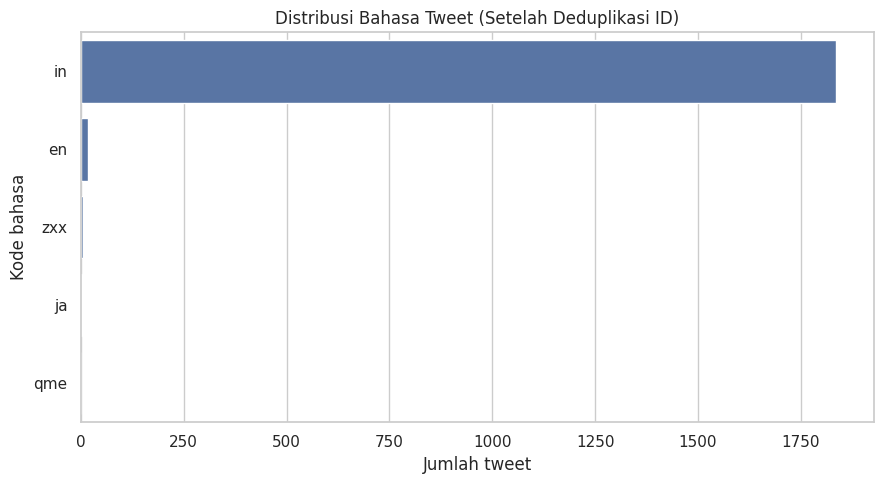

Distribusi bahasa pada periode penelitian:


,jumlah
lang,
in,872
en,6
zxx,3
ja,2


In [ ]:
if 'lang' in eda.columns:
    bahasa = (eda['lang'].fillna('missing').value_counts()
              .rename_axis('kode_bahasa').reset_index(name='jumlah'))
    bahasa['persentase'] = (bahasa['jumlah'] / len(eda) * 100).round(2)
    display(bahasa)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=bahasa, x='jumlah', y='kode_bahasa')
    plt.title('Distribusi Bahasa Tweet (Setelah Deduplikasi ID)')
    plt.xlabel('Jumlah tweet')
    plt.ylabel('Kode bahasa')
    plt.tight_layout()
    plt.show()

    if 'lang' in data_periode.columns:
        print("Distribusi bahasa pada periode penelitian:")
        display(data_periode['lang'].value_counts(dropna=False).to_frame('jumlah'))

## 9. Distribusi tweet berdasarkan jenis interaksi

In [ ]:
for col in ['isReply', 'isRetweet', 'isQuote', 'isPinned']:
    if col in eda.columns:
        print(f"Distribusi {col}:")
        display(eda[col].value_counts(dropna=False).to_frame('jumlah'))

Distribusi isReply:


,jumlah
isReply,
False,1503
True,359


Distribusi isRetweet:


,jumlah
isRetweet,
NaN,1452
False,331
True,79


Distribusi isQuote:


,jumlah
isQuote,
NaN,1460
False,342
True,60


Distribusi isPinned:


,jumlah
isPinned,
False,1862


## 10. Analisis jumlah tweet per hari

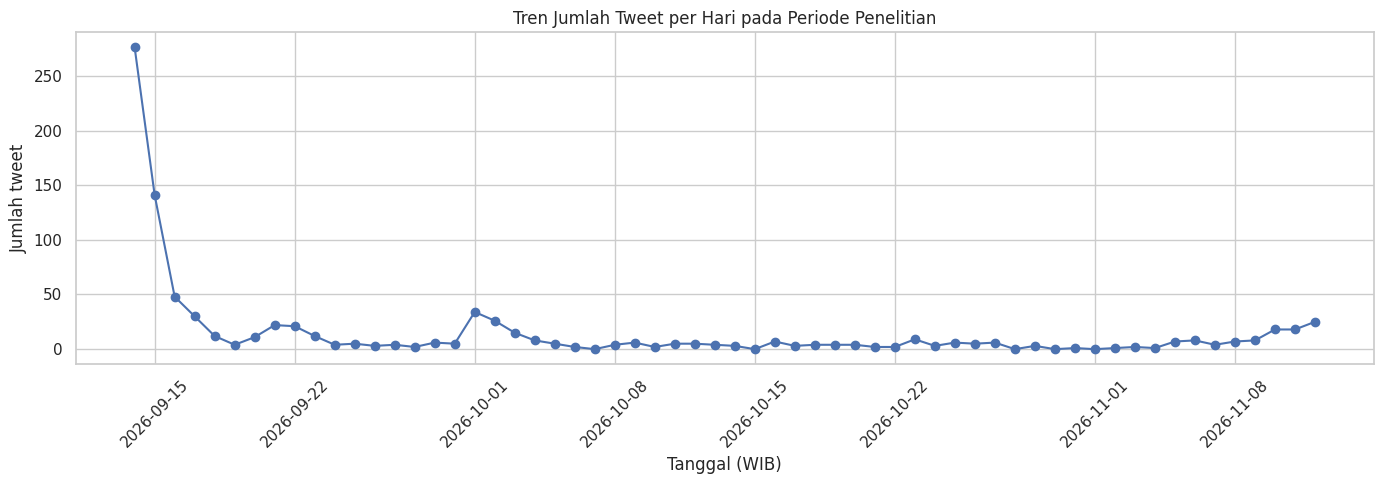

10 tanggal dengan jumlah tweet terbanyak:


,createdAt_wib,jumlah_tweet
0,2026-09-14 00:00:00+07:00,276
1,2026-09-15 00:00:00+07:00,141
2,2026-09-16 00:00:00+07:00,48
17,2026-10-01 00:00:00+07:00,34
3,2026-09-17 00:00:00+07:00,30
18,2026-10-02 00:00:00+07:00,26
59,2026-11-12 00:00:00+07:00,25
7,2026-09-21 00:00:00+07:00,22
8,2026-09-22 00:00:00+07:00,21
57,2026-11-10 00:00:00+07:00,18


In [ ]:
# Gunakan data periode penelitian agar grafik fokus pada rentang yang ditentukan.
tanggal_harian = (
    data_periode.dropna(subset=['createdAt_wib'])
    .set_index('createdAt_wib')
    .resample('D')
    .size()
    .rename('jumlah_tweet')
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(tanggal_harian['createdAt_wib'], tanggal_harian['jumlah_tweet'],
         marker='o', linewidth=1.5)
plt.title('Tren Jumlah Tweet per Hari pada Periode Penelitian')
plt.xlabel('Tanggal (WIB)')
plt.ylabel('Jumlah tweet')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("10 tanggal dengan jumlah tweet terbanyak:")
display(tanggal_harian.sort_values('jumlah_tweet', ascending=False).head(10))

## 11. Statistik interaksi tweet

Statistik interaksi seluruh data unik:


,count,mean,std,min,25%,50%,75%,max
retweetCount,1862.0,116.39,808.44,0.0,0.00,2.0,11.0,19475.0
replyCount,1862.0,20.89,111.82,0.0,0.00,1.0,7.0,3104.0
likeCount,1862.0,491.30,2891.83,0.0,2.00,8.0,36.0,46883.0
quoteCount,1862.0,19.39,209.16,0.0,0.00,0.0,1.0,5911.0
viewCount,1862.0,41685.03,310384.81,1.0,474.75,1508.0,7386.0,11089814.0
bookmarkCount,1862.0,37.54,281.40,0.0,0.00,0.0,3.0,8828.0


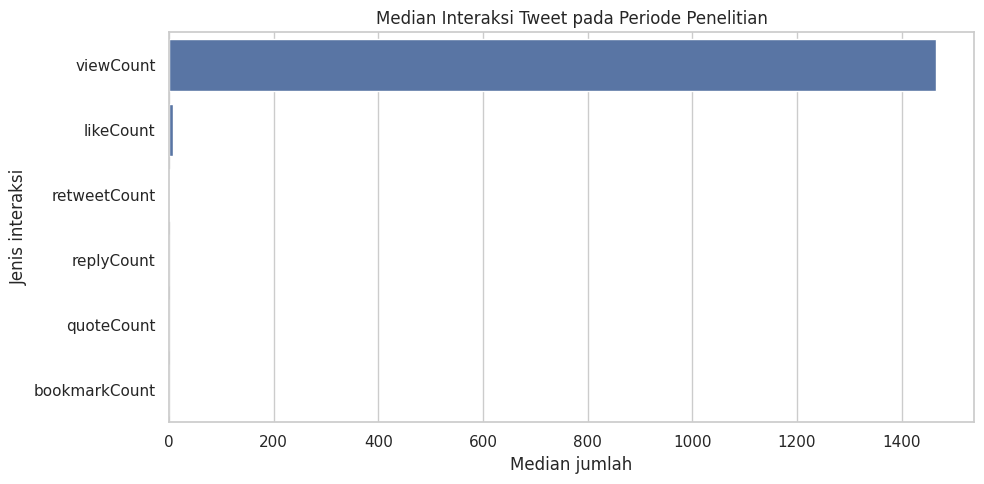

In [ ]:
kolom_interaksi = [
    c for c in ['retweetCount', 'replyCount', 'likeCount',
                'quoteCount', 'viewCount', 'bookmarkCount']
    if c in eda.columns
]

for col in kolom_interaksi:
    eda[col] = pd.to_numeric(eda[col], errors='coerce')
    data_periode[col] = pd.to_numeric(data_periode[col], errors='coerce')

if kolom_interaksi:
    print("Statistik interaksi seluruh data unik:")
    display(eda[kolom_interaksi].describe().T.round(2))

    median_interaksi = data_periode[kolom_interaksi].median().sort_values(ascending=False)
    plt.figure(figsize=(10, 5))
    sns.barplot(x=median_interaksi.values, y=median_interaksi.index)
    plt.title('Median Interaksi Tweet pada Periode Penelitian')
    plt.xlabel('Median jumlah')
    plt.ylabel('Jenis interaksi')
    plt.tight_layout()
    plt.show()

## 12. Analisis panjang teks dan jumlah kata

,panjang_karakter,jumlah_kata
count,883.00,883.00
mean,439.94,58.86
std,594.66,79.83
min,0.00,0.00
25%,133.50,18.00
50%,251.00,34.00
75%,439.00,57.50
max,3998.00,564.00


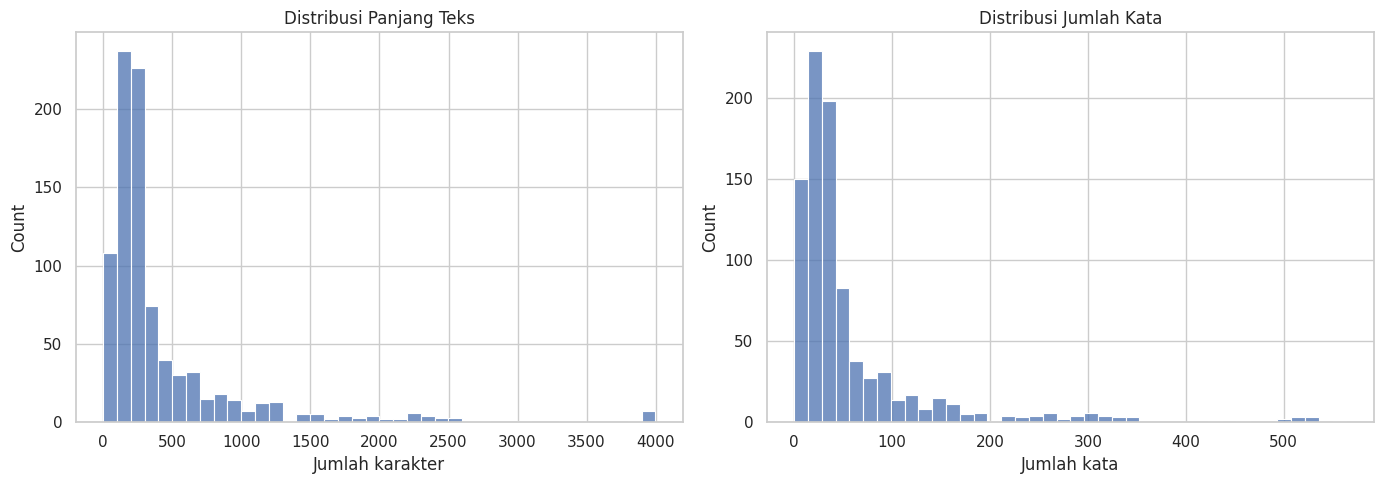

In [ ]:
if 'text' not in data_periode.columns:
    raise KeyError("Kolom 'text' tidak ditemukan.")

data_periode['text'] = data_periode['text'].fillna('').astype(str)
data_periode['panjang_karakter'] = data_periode['text'].str.len()
data_periode['jumlah_kata'] = data_periode['text'].str.split().str.len()

display(data_periode[['panjang_karakter', 'jumlah_kata']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data_periode['panjang_karakter'], bins=40, ax=axes[0])
axes[0].set_title('Distribusi Panjang Teks')
axes[0].set_xlabel('Jumlah karakter')

sns.histplot(data_periode['jumlah_kata'], bins=40, ax=axes[1])
axes[1].set_title('Distribusi Jumlah Kata')
axes[1].set_xlabel('Jumlah kata')

plt.tight_layout()
plt.show()

## 13. Frekuensi kata yang paling sering muncul

,kata,frekuensi
0,purbaya,1560
1,menteri,639
2,prabowo,596
3,keuangan,535
4,suahasil,396
5,dicopot,386
6,menkeu,372
7,presiden,302
8,sadewa,277
9,nazara,265


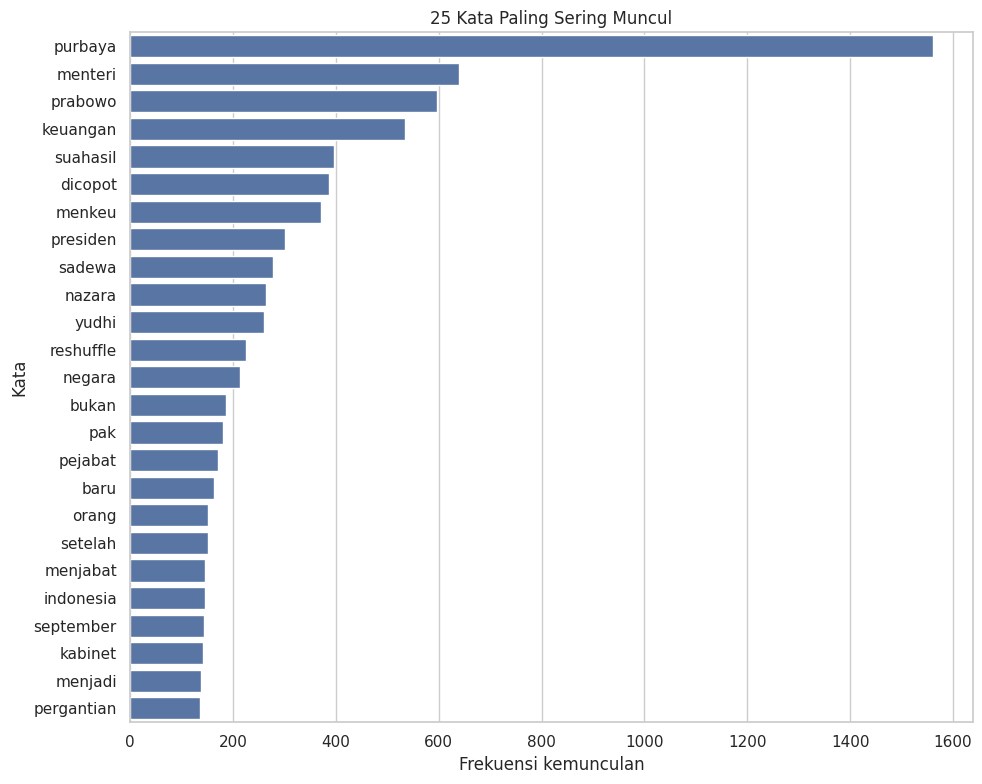

In [ ]:
# Pembersihan ringan untuk eksplorasi kata, bukan preprocessing final model.
stopwords_id = set([
    'yang','dan','di','ke','dari','ini','itu','untuk','dengan','pada','ada',
    'karena','dalam','akan','sudah','jadi','juga','atau','saja','saya','kami',
    'kita','mereka','dia','nya','agar','lebih','bisa','tidak','tak','dapat',
    'oleh','sebagai','tersebut','dalam','saat','dalam','https','http','co',
    'rt','amp','yg','aja','nya','lah','kah','pun'
])

def token_eda(teks):
    teks = teks.lower()
    teks = re.sub(r'https?://\S+|www\.\S+', ' ', teks)
    teks = re.sub(r'@\w+', ' ', teks)
    teks = teks.replace('#', ' ')
    teks = re.sub(r'[^a-zA-ZÀ-ÿ\s]', ' ', teks)
    return [kata for kata in teks.split()
            if len(kata) > 2 and kata not in stopwords_id]

semua_token = []
for teks in data_periode['text']:
    semua_token.extend(token_eda(teks))

frekuensi = Counter(semua_token)
top_kata = pd.DataFrame(frekuensi.most_common(25),
                        columns=['kata', 'frekuensi'])

display(top_kata)

plt.figure(figsize=(10, 8))
sns.barplot(data=top_kata, x='frekuensi', y='kata')
plt.title('25 Kata Paling Sering Muncul')
plt.xlabel('Frekuensi kemunculan')
plt.ylabel('Kata')
plt.tight_layout()
plt.show()

## 14. WordCloud keseluruhan tweet

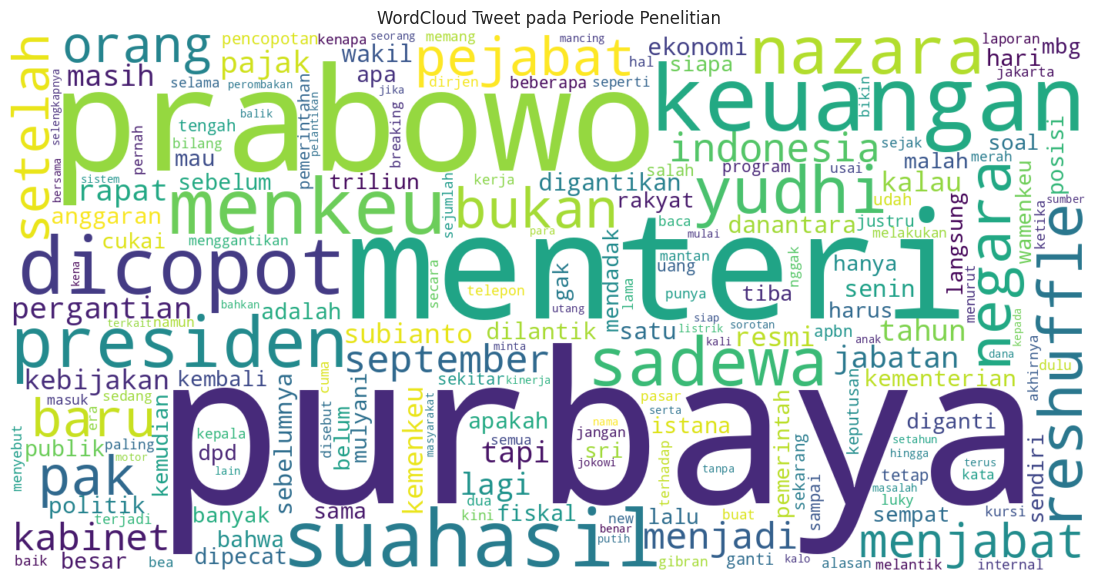

In [ ]:
if len(semua_token) > 0:
    wc = WordCloud(
        width=1400, height=700,
        background_color='white',
        collocations=False
    ).generate(' '.join(semua_token))

    plt.figure(figsize=(15, 7))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title('WordCloud Tweet pada Periode Penelitian')
    plt.show()
else:
    print("Tidak ada token yang dapat divisualisasikan.")

## 15. Tweet dengan interaksi tertinggi

In [ ]:
kolom_tampil = [c for c in [
    'createdAt', 'text', 'likeCount', 'retweetCount',
    'replyCount', 'quoteCount', 'viewCount', 'url'
] if c in data_periode.columns]

if 'likeCount' in data_periode.columns:
    print("10 tweet dengan jumlah like tertinggi:")
    display(data_periode.sort_values('likeCount', ascending=False)[kolom_tampil].head(10))

if 'viewCount' in data_periode.columns:
    print("10 tweet dengan jumlah view tertinggi:")
    display(data_periode.sort_values('viewCount', ascending=False)[kolom_tampil].head(10))

10 tweet dengan jumlah like tertinggi:


,createdAt,text,likeCount,retweetCount,replyCount,quoteCount,viewCount,url
2096,Fri Oct 23 01:06:25 +0000 2026,purbaya cerita prabowo kalo terima laporan jelek itu langsung tidak suka \n\ntiap dia laporan ke prabowo ada yang je...,46883,11183,858,2641,1272790,https://x.com/LambeSahamjja/status/2113436850094526570
2194,Thu Oct 01 08:16:40 +0000 2026,BREAKING NEWS \nLUKY AFIRMAN DI LANTIK PRABOWO JADI WAKIL MENTERI KEUANGAN \n\nPERNAH DI COPOT PURBAYA KARNA LOLOSKA...,41364,12992,1989,3182,1419128,https://x.com/LambeSahamjja/status/2105572594531619225
2334,Mon Sep 14 08:31:57 +0000 2026,BREAKING NEWS \nPURBAYA DI PECAT PRABOWO DARI MENKEU,38988,3936,1261,4570,11089814,https://x.com/LambeSahamjja/status/2099415846351413284
2261,Tue Sep 15 00:26:57 +0000 2026,"INFO A1\n\n• Purbaya tiba-tiba diganti kabarnya pemicunya bukan soal kinerja.\n\n• Pada 10 September, Purbaya melaku...",32355,7828,495,772,2366801,https://x.com/sibambaang/status/2099656178347495856
2272,Mon Sep 14 12:46:51 +0000 2026,- Purbaya dipecat \n- Menkeu terbaru Suahasil Nazara\n\nTapi Presiden dan wapres kita masih Prabowo Gibran. Menteri ...,26660,9381,104,122,509776,https://x.com/whiterosestea/status/2099479992983798107
635,Wed Sep 16 01:15:23 +0000 2026,In Case You Missed It: Purbaya Akui Rombak 400 Pejabat Kemenkeu Jadi Salah Satu Pemicu Dicopot,23032,4332,93,214,434698,https://x.com/tempodotco/status/2100030756068409498
657,Mon Sep 14 11:42:05 +0000 2026,"Purbaya dicopot ?\nPigai stay ?\nRaja juli stay ?\nBahlil stay ?\nWoii Negara bgstttt, \nare you fucking kidding me ...",20222,4264,135,58,278959,https://x.com/GusDikaOfficial/status/2099463695445442798
2255,Tue Sep 15 10:59:22 +0000 2026,"Pak Purbaya mau sapu bersih pejabat korup tapi malah dipecat, ini mah beneran fix prabowo gak suka kalo anggaran mbg...",20034,5088,49,88,178301,https://x.com/xyshulu/status/2099815332949205358
3215,Mon Sep 14 13:53:08 +0000 2026,"Purbaya hari ini - 14 September 2026 :\n\n- Lagi asik rapat dengan DPD, dan berbagai lembaga dari pagi jam 10.00\n- ...",13579,1608,119,106,685169,https://x.com/Hidupsebagai62/status/2099496673303216469
2252,Wed Sep 16 03:42:43 +0000 2026,Buat yang masih ga paham kenapa Purbaya dipecat\n\n> Kemenkeu punya dana SAL (Saldo Anggaran Lebih) yang merupakan c...,13175,2357,244,192,888208,https://x.com/mhuseinali/status/2100067831794774316


10 tweet dengan jumlah view tertinggi:


,createdAt,text,likeCount,retweetCount,replyCount,quoteCount,viewCount,url
2334,Mon Sep 14 08:31:57 +0000 2026,BREAKING NEWS \nPURBAYA DI PECAT PRABOWO DARI MENKEU,38988,3936,1261,4570,11089814,https://x.com/LambeSahamjja/status/2099415846351413284
164,Mon Sep 14 08:37:18 +0000 2026,BREAKING ?ï¸?\n\nSuahasil Nazara menjadi Menteri Keuangan (Menkeu) menggantikan Purbaya Yudhi Sadewa.\n\nDitengah be...,4178,576,168,493,3322229,https://x.com/pw_gun/status/2099417192551117267
2261,Tue Sep 15 00:26:57 +0000 2026,"INFO A1\n\n• Purbaya tiba-tiba diganti kabarnya pemicunya bukan soal kinerja.\n\n• Pada 10 September, Purbaya melaku...",32355,7828,495,772,2366801,https://x.com/sibambaang/status/2099656178347495856
837,Mon Sep 14 11:18:50 +0000 2026,Purbaya dapat telpon darurat dari istana di tengah rapat. ternyata itu adalah rapat terakhirnya sebagai Menkeu\n___...,3494,408,57,107,2247218,https://x.com/txtdrimedia/status/2099457843858751675
166,Mon Sep 14 08:30:29 +0000 2026,"[BREAKING] Menkeu Purbaya di-reshuffle, Wamenkeu Suahasil Nazara dilantik menjadi Menteri Keuangan.",7181,1455,236,1182,1512793,https://x.com/BigAlphaID/status/2099415475629514757
2194,Thu Oct 01 08:16:40 +0000 2026,BREAKING NEWS \nLUKY AFIRMAN DI LANTIK PRABOWO JADI WAKIL MENTERI KEUANGAN \n\nPERNAH DI COPOT PURBAYA KARNA LOLOSKA...,41364,12992,1989,3182,1419128,https://x.com/LambeSahamjja/status/2105572594531619225
655,Mon Sep 14 12:01:01 +0000 2026,Meeting terakhir Purbaya sblm dicopot.\n.. selama 1 tahun saya tidak pernah menaikan tarif pajak! https://t.co/GvBOC...,7530,1279,118,39,1303690,https://x.com/BosPurwa/status/2099468459688317374
2096,Fri Oct 23 01:06:25 +0000 2026,purbaya cerita prabowo kalo terima laporan jelek itu langsung tidak suka \n\ntiap dia laporan ke prabowo ada yang je...,46883,11183,858,2641,1272790,https://x.com/LambeSahamjja/status/2113436850094526570
167,Mon Sep 14 08:29:37 +0000 2026,"Menteri Keuangan (Menkeu) Purbaya Yudhi Sadewa kena reshuffle. Kini, posisinya digantikan oleh wakilnya, Suahasil Na...",6068,1424,431,1111,1206840,https://x.com/kumparan/status/2099415258406494527
2252,Wed Sep 16 03:42:43 +0000 2026,Buat yang masih ga paham kenapa Purbaya dipecat\n\n> Kemenkeu punya dana SAL (Saldo Anggaran Lebih) yang merupakan c...,13175,2357,244,192,888208,https://x.com/mhuseinali/status/2100067831794774316


## 16. Menyaring data bahasa Indonesia dan mengekspor hasil EDA

In [ ]:
# Simpan subset bahasa Indonesia pada periode penelitian.
if 'lang' in data_periode.columns:
    data_id = data_periode[data_periode['lang'].eq('in')].copy()
else:
    data_id = data_periode.copy()

print("Jumlah tweet unik periode penelitian:", len(data_periode))
print("Jumlah tweet berbahasa Indonesia:", len(data_id))

# Pilih kolom yang berguna untuk tahapan anotasi sentimen.
kolom_penting = [c for c in [
    'id', 'createdAt', 'text', 'lang', 'url',
    'retweetCount', 'replyCount', 'likeCount',
    'quoteCount', 'viewCount'
] if c in data_id.columns]

data_analisis = data_id[kolom_penting].copy()
display(data_analisis.head())

output_csv = '/content/data_twitter_eda_periode_indonesia.csv'
data_analisis.to_csv(output_csv, index=False, encoding='utf-8-sig')
print("File tersimpan:", output_csv)

from google.colab import files
files.download(output_csv)

Jumlah tweet unik periode penelitian: 883
Jumlah tweet berbahasa Indonesia: 872


,id,createdAt,text,lang,url,retweetCount,replyCount,likeCount,quoteCount,viewCount
0,2106613680893054987,Sun Oct 04 05:13:35 +0000 2026,Kembalinya Luky Alfirman ke lingkar pimpinan Kementerian Keuangan (Kemenkeu) memicu sorotan publik. \n\nSetelah semp...,in,https://x.com/suaradotcom/status/2106613680893054987,3,0,4,1,814
1,2106378191623586058,Sat Oct 03 13:37:50 +0000 2026,Kebijakan tanda bintang itu dihapuskan ketika purbaya menjabat.\n\nhttps://t.co/0GbtCZLMQN.,in,https://x.com/VeritasArdentur/status/2106378191623586058,1,3,10,0,2967
2,2106355674405912867,Sat Oct 03 12:08:21 +0000 2026,Itu paragraf pertama ngomongin sistem bintang di DJA. Bukan penandatanganan DIPA.\n\nSudah basi dan tidak berlaku di...,in,https://x.com/VeritasArdentur/status/2106355674405912867,1,1,7,0,2256
3,2106336567631679547,Sat Oct 03 10:52:26 +0000 2026,"Itu ketika tanda bintang masih berlaku.\n\nPurbaya sudah jelas2 menghapus sistem tersebut, dan sudah dikomunikasikan...",in,https://x.com/VeritasArdentur/status/2106336567631679547,3,1,16,0,2888
4,2106331994527559750,Sat Oct 03 10:34:15 +0000 2026,Gini aja. Tunjukkan saya aturannya bahwa uang negara bisa cair tanpa ttd menteri.\n\nKalau perkara purbaya menghapus...,in,https://x.com/VeritasArdentur/status/2106331994527559750,14,3,40,0,6184


File tersimpan: /content/data_twitter_eda_periode_indonesia.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>